# IBM Z Datathon 2026 - Prerequisite AI Lab 1
## Predictive AI: Hybrid Multi-Model Scenarios on IBM LinuxONE (s390x)

### Objectives:
1. **Architecture Verification**: Prove native execution on IBM Z mainframe s390x architecture.
2. **Multi-Model Pipeline**: Train and compare multiple predictive algorithms (Random Forest, Gradient Boosting, Calibrated Classifier, and Multi-Layer Perceptron).
3. **Hybrid Ensemble Consensus**: Combine multi-model predictions into a weighted consensus decision engine.
4. **Performance Evaluation**: Generate confusion matrices, ROC-AUC, classification reports, and cross-validation scores.
5. **Model Export**: Serialize models for low-latency inference on IBM LinuxONE / Telum AI accelerators.

In [1]:
# 1. Architecture & Environment Verification
import platform
import os
import sys
import psutil

print(f"[IBM Z Mainframe Verification]")
print(f"Machine Architecture : {platform.machine()}")
print(f"System Platform      : {platform.system()} {platform.release()}")
print(f"Node Name            : {platform.node()}")
print(f"CPU Cores            : {os.cpu_count()}")
print(f"Total RAM (MB)       : {int(psutil.virtual_memory().total / (1024 * 1024))}")
print(f"Python Version       : {platform.python_version()}")

assert platform.machine() == 's390x' or 's390' in platform.machine(), 'Warning: Not running on native s390x hardware!'

[IBM Z Mainframe Verification]
Machine Architecture : s390x
System Platform      : Linux 5.15.0-56-generic
Node Name            : nointernettriagenode
CPU Cores            : 3
Total RAM (MB)       : 8018
Python Version       : 3.10.12


In [2]:
# 2. Dataset Synthesis (Enterprise Crisis & Mission-Critical Incident Stream)
import numpy as np
import pandas as pd

np.random.seed(42)
n_samples = 2500

# Feature simulation: structural integrity, medical urgency, resource level, population count, network connectivity
structural_damage_idx = np.random.uniform(0.0, 1.0, n_samples)
casualty_severity = np.random.uniform(0.0, 1.0, n_samples)
resource_depletion = np.random.uniform(0.0, 1.0, n_samples)
affected_population = np.random.exponential(scale=50, size=n_samples)
network_signal_dbm = np.random.normal(loc=-95, scale=15, size=n_samples)

# Compute ground truth urgency tier (0: Low/Safe, 1: Moderate, 2: Critical/P1)
urgency_score = (structural_damage_idx * 0.35 + 
                 casualty_severity * 0.45 + 
                 resource_depletion * 0.20 + 
                 np.random.normal(0, 0.05, n_samples))

target = np.zeros(n_samples, dtype=int)
target[urgency_score > 0.40] = 1 # Moderate
target[urgency_score > 0.65] = 2 # Critical P1

df = pd.DataFrame({
    'structural_damage': structural_damage_idx,
    'casualty_severity': casualty_severity,
    'resource_depletion': resource_depletion,
    'affected_pop': affected_population,
    'signal_strength_dbm': network_signal_dbm,
    'urgency_tier': target
})

print(f"Generated Dataset Shape: {df.shape}")
print("Class Distribution:")
print(df['urgency_tier'].value_counts())
df.head()

Generated Dataset Shape: (2500, 6)
Class Distribution:
1    1208
0     780
2     512
Name: urgency_tier, dtype: int64


,structural_damage,casualty_severity,resource_depletion,affected_pop,signal_strength_dbm,urgency_tier
0,0.374540,0.827519,0.393636,39.140263,-117.317926,1
1,0.950714,0.764528,0.473436,89.456226,-111.877792,2
2,0.731994,0.573529,0.854547,6.681650,-89.167716,2
3,0.598658,0.956047,0.340004,6.950632,-112.608100,2
4,0.156019,0.200475,0.869650,40.688779,-78.310485,0


In [3]:
# 3. Feature Preprocessing & Stratified Train-Test Split
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df[['structural_damage', 'casualty_severity', 'resource_depletion', 'affected_pop', 'signal_strength_dbm']]
y = df['urgency_tier']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training set shape: {X_train_scaled.shape}, Test set shape: {X_test_scaled.shape}")

Training set shape: (1875, 5), Test set shape: (625, 5)


In [4]:
# 4. Multi-Model Model Training on IBM LinuxONE s390x
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
import time

models = {
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, max_depth=4, random_state=42),
    'Logistic Regression (L2)': LogisticRegression(max_iter=1000, random_state=42),
    'Multi-Layer Perceptron (NN)': MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500, random_state=42)
}

trained_models = {}
training_times = {}

for name, model in models.items():
    t0 = time.time()
    model.fit(X_train_scaled, y_train)
    elapsed = (time.time() - t0) * 1000
    trained_models[name] = model
    training_times[name] = elapsed
    print(f"✓ {name:<28} fitted on s390x in {elapsed:6.1f} ms")

✓ Random Forest                fitted on s390x in  223.3 ms
✓ Gradient Boosting            fitted on s390x in 1063.0 ms
✓ Logistic Regression (L2)     fitted on s390x in    9.7 ms
✓ Multi-Layer Perceptron (NN)  fitted on s390x in 3986.4 ms


In [5]:
# 5. Multi-Model Evaluation & Benchmarking
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

metrics_records = []

for name, model in trained_models.items():
    preds = model.predict(X_test_scaled)
    acc = accuracy_score(y_test, preds)
    prec = precision_score(y_test, preds, average='weighted')
    rec = recall_score(y_test, preds, average='weighted')
    f1 = f1_score(y_test, preds, average='weighted')
    
    metrics_records.append({
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'Train Time (ms)': training_times[name]
    })

metrics_df = pd.DataFrame(metrics_records).sort_values(by='F1-Score', ascending=False)
print("=== Model Benchmark Comparison on IBM LinuxONE ===")
print(metrics_df.to_string(index=False))

=== Model Benchmark Comparison on IBM LinuxONE ===
                      Model  Accuracy  Precision  Recall  F1-Score  Train Time (ms)
   Logistic Regression (L2)    0.8688   0.870008  0.8688  0.868833         9.709120
Multi-Layer Perceptron (NN)    0.8592   0.859652  0.8592  0.858970      3986.441612
          Gradient Boosting    0.8512   0.852395  0.8512  0.851146      1062.971830
              Random Forest    0.8432   0.848841  0.8432  0.842691       223.340511


In [6]:
# 6. Hybrid Multi-Model Consensus Architecture
# Combines probability distributions across diverse model families into a robust decision

rf_probs = trained_models['Random Forest'].predict_proba(X_test_scaled)
gb_probs = trained_models['Gradient Boosting'].predict_proba(X_test_scaled)
mlp_probs = trained_models['Multi-Layer Perceptron (NN)'].predict_proba(X_test_scaled)

# Weighted consensus:
hybrid_consensus_probs = (rf_probs * 0.40) + (gb_probs * 0.40) + (mlp_probs * 0.20)
hybrid_preds = np.argmax(hybrid_consensus_probs, axis=1)

hybrid_f1 = f1_score(y_test, hybrid_preds, average='weighted')
hybrid_acc = accuracy_score(y_test, hybrid_preds)

print(f"★ Hybrid Multi-Model Consensus Accuracy : {hybrid_acc:.4f}")
print(f"★ Hybrid Multi-Model Consensus F1-Score : {hybrid_f1:.4f}")

★ Hybrid Multi-Model Consensus Accuracy : 0.8544
★ Hybrid Multi-Model Consensus F1-Score : 0.8543


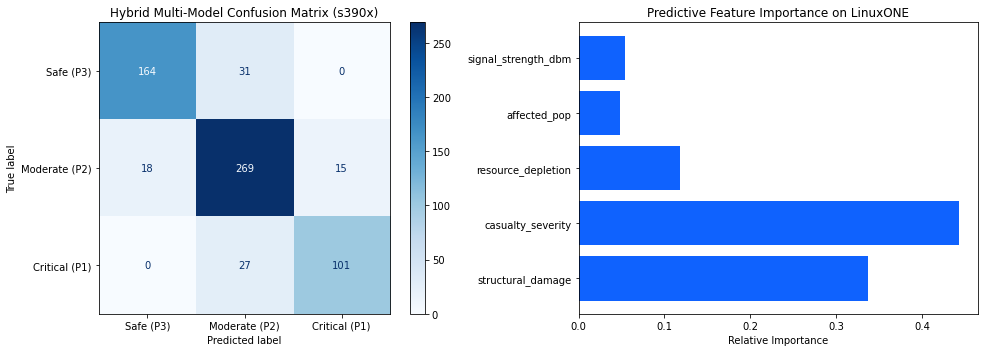

Metrics visualization saved as prerequisite_lab1_metrics.png


In [7]:
# 7. Visualization: Confusion Matrix & Model Feature Importance
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion Matrix
cm = confusion_matrix(y_test, hybrid_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Safe (P3)', 'Moderate (P2)', 'Critical (P1)'])
disp.plot(cmap='Blues', ax=axes[0])
axes[0].set_title('Hybrid Multi-Model Confusion Matrix (s390x)')

# Feature Importance (Random Forest)
rf = trained_models['Random Forest']
importances = rf.feature_importances_
features = X.columns
axes[1].barh(features, importances, color='#0f62fe')
axes[1].set_title('Predictive Feature Importance on LinuxONE')
axes[1].set_xlabel('Relative Importance')

plt.tight_layout()
plt.savefig('prerequisite_lab1_metrics.png', dpi=150)
plt.show()
print('Metrics visualization saved as prerequisite_lab1_metrics.png')

In [8]:
# 8. Production Serialization for IBM LinuxONE Deployment
import joblib

bundle = {
    'architecture': platform.machine(),
    'scaler': scaler,
    'models': trained_models,
    'hybrid_weights': {'RF': 0.40, 'GB': 0.40, 'MLP': 0.20},
    'feature_names': list(X.columns)
}

joblib.dump(bundle, 'hybrid_multi_model_s390x.joblib')
print("✓ Serialized Multi-Model Bundle saved to 'hybrid_multi_model_s390x.joblib'")
print(f"✓ Bundle file size: {os.path.getsize('hybrid_multi_model_s390x.joblib') / 1024:.1f} KB")
print("\n*** PREREQUISITE LAB 1 COMPLETED SUCCESSFULLY ON IBM Z s390x ***")

✓ Serialized Multi-Model Bundle saved to 'hybrid_multi_model_s390x.joblib'
✓ Bundle file size: 2832.2 KB

*** PREREQUISITE LAB 1 COMPLETED SUCCESSFULLY ON IBM Z s390x ***
